# Test: balkberäkning (balk)

Kontrollerar `kb.balk` mot handboksformler för statiskt bestämda och obestämda balkar. Laster är positiva nedåt, M positivt när underkanten är dragen och w positiv nedåt.

Kör med **Run All**. Kerneln ska vara `.venv` i repot.

- ✔ kontrollen gick igenom
- ✘ känt fel: fel som redan är kända och inte rättade än
- ✘ FEL: nytt fel

In [27]:
import math
import kthbygg as kb
from kontroll import kolla, kolla_fel, klass, utskrift, sammanfattning, nollställ

nollställ()

## Indata och diagram

L = 6, q = 10, P = 20, EI = 1000 (godtyckliga men konsekventa enheter).

Varje fall ritas med `visa(r)`: balken samt N-, V-, M- och w-diagram, med positivt M nedåt (dragen sida). Sätt `INTERAKTIV = True` för att i stället få plotly-diagram där muspekaren visar värdena längs balken.

Cellen skriver ut vilken kthbygg som används. Sökvägen ska sluta på `Desktop\kthbygg\kthbygg\balk.py`, annars är fel kernel vald.

In [28]:
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import display
import kthbygg.balk
from kthbygg.balk import Balk

print("kthbygg.balk från:", kthbygg.balk.__file__)

L, q, P, EI = 6.0, 10.0, 20.0, 1000.0
INTERAKTIV = False


def visa(r, storheter="NVMw"):
    if INTERAKTIV:
        display(r.rita_interaktiv(storheter, dragen_sida=True))
    else:
        fig = r.rita(storheter, dragen_sida=True)
        display(fig)
        plt.close(fig)

kthbygg.balk från: C:\Users\GTSA - Infinity\Desktop\kthbygg\kthbygg\balk.py


## Fritt upplagd balk, jämnt utbredd last

R = qL/2, M_max = qL²/8 i mitten, w_max = 5qL⁴/(384EI).

✔            R_A: fick 30, väntat 30
✔            M_max: fick 45, väntat 45
✔            x för M_max: fick 3, väntat 3
✔            w_max: fick 0.16875, väntat 0.16875
✔            statiskt bestämd: fick 0, väntat 0


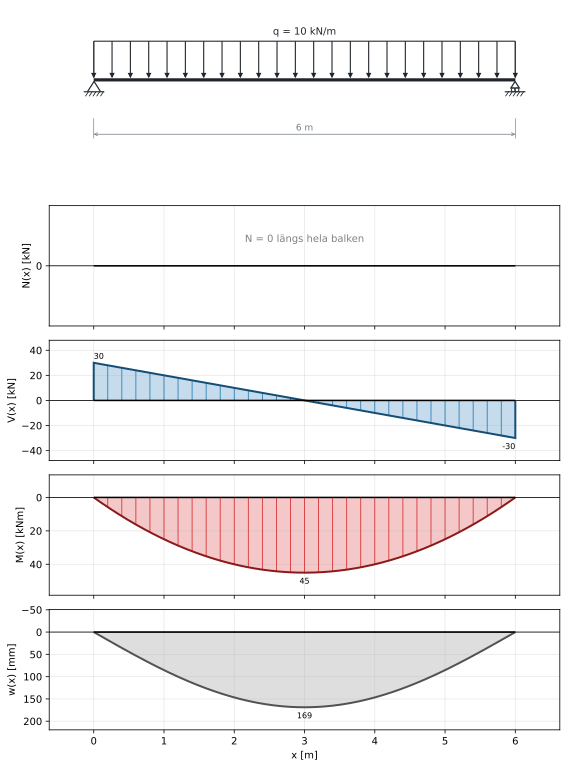

In [29]:
r = Balk(L, EI).stöd(0, "led").stöd(L, "rull").utbredd_last(q).lös()
kolla("R_A", lambda: r.reaktioner[0]["V"], q * L / 2)
kolla("M_max", lambda: r.extremvärden("M")[0][1], q * L**2 / 8)
kolla("x för M_max", lambda: r.extremvärden("M")[0][0], L / 2)
kolla("w_max", lambda: r.extremvärden("w")[0][1], 5 * q * L**4 / (384 * EI))
kolla("statiskt bestämd", lambda: r.grad, 0)
visa(r)

## Fritt upplagd balk, punktlast i a = 2

M = Pab/L och w = Pa²b²/(3EIL) under lasten. Tvärkraften gör ett språng på P.

✔            M(a): fick 26.6667, väntat 26.6667
✔            w(a): fick 0.0711111, väntat 0.0711111
✔            V strax vänster om lasten: fick 13.3333, väntat 13.3333
✔            V strax höger om lasten: fick -6.66667, väntat -6.66667


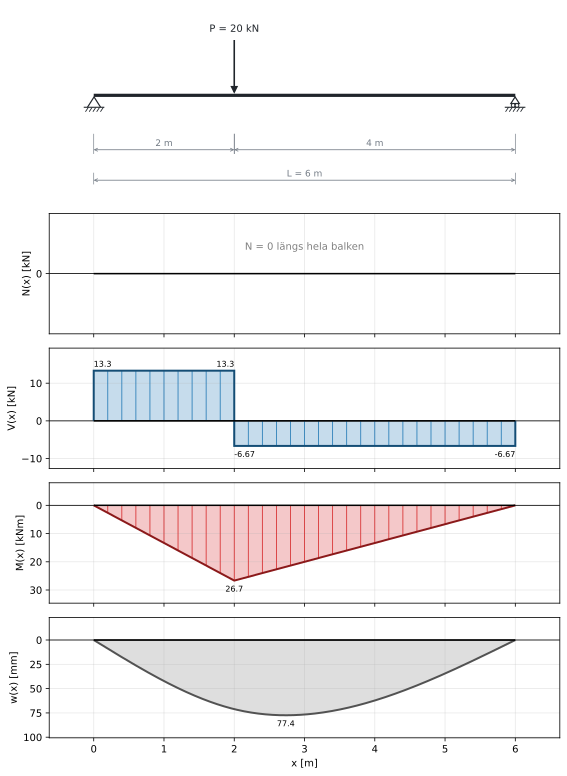

In [30]:
a, b = 2.0, 4.0
r = Balk(L, EI).stöd(0, "led").stöd(L, "rull").punktlast(a, P).lös()
kolla("M(a)", lambda: r.M(a), P * a * b / L)
kolla("w(a)", lambda: r.w(a), P * a**2 * b**2 / (3 * EI * L))
kolla("V strax vänster om lasten", lambda: r.V(a, "vänster"), P * b / L)
kolla("V strax höger om lasten", lambda: r.V(a), -P * a / L)
visa(r)

## Konsol med punktlast i spetsen

Inspänningsmoment PL (moturs), M(0) = −PL, w(L) = PL³/(3EI).

✔            R_V: fick 20, väntat 20
✔            R_M: fick 120, väntat 120
✔            M(0): fick -120, väntat -120
✔            w(L): fick 1.44, väntat 1.44


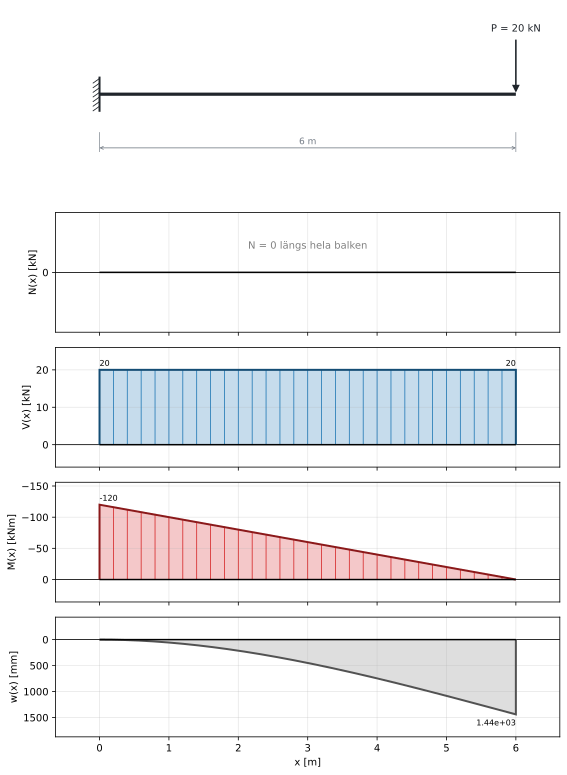

In [31]:
r = Balk(L, EI).stöd(0, "fast").punktlast(L, P).lös()
kolla("R_V", lambda: r.reaktioner[0]["V"], P)
kolla("R_M", lambda: r.reaktioner[0]["M"], P * L)
kolla("M(0)", lambda: r.M(0), -P * L)
kolla("w(L)", lambda: r.w(L), P * L**3 / (3 * EI))
visa(r)

## Fast inspänd i båda ändar, jämn last

M_ände = −qL²/12, M_mitt = qL²/24, w_mitt = qL⁴/(384EI). Tre gånger statiskt obestämd totalt: två i böjning och en axiellt.

✔            M(0): fick -30, väntat -30
✔            M(L/2): fick 15, väntat 15
✔            w(L/2): fick 0.03375, väntat 0.03375
✔            grad 3: fick 2, väntat 2


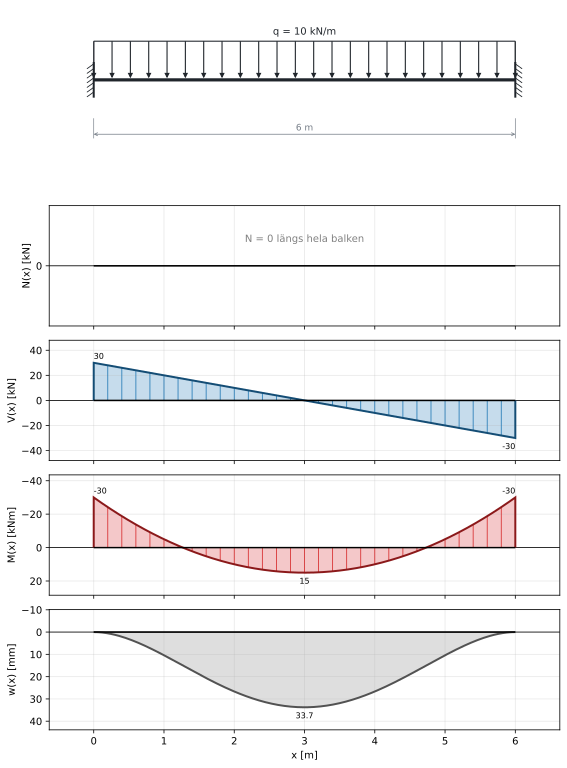

In [32]:
r = Balk(L, EI).stöd(0, "fast").stöd(L, "fast").utbredd_last(q).lös()
kolla("M(0)", lambda: r.M(0), -q * L**2 / 12)
kolla("M(L/2)", lambda: r.M(L / 2), q * L**2 / 24)
kolla("w(L/2)", lambda: r.w(L / 2), q * L**4 / (384 * EI))
kolla("grad 3", lambda: r.grad, 3)
visa(r)

## Inspänd och rullager, jämn last

R_B = 3qL/8, M(0) = −qL²/8, M_max = 9qL²/128 vid x = 5L/8. En gång statiskt obestämd.

✔            R_B: fick 22.5, väntat 22.5
✔            M(0): fick -45, väntat -45
✔            M_max: fick 25.3125, väntat 25.3125
✔            x för M_max: fick 3.75, väntat 3.75
✔            grad 1: fick 1, väntat 1


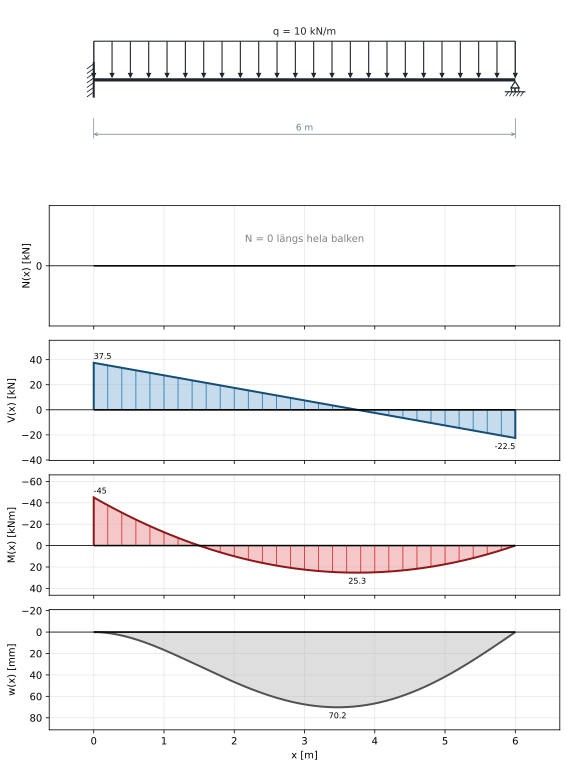

In [33]:
r = Balk(L, EI).stöd(0, "fast").stöd(L, "rull").utbredd_last(q).lös()
kolla("R_B", lambda: r.reaktioner[L]["V"], 3 * q * L / 8)
kolla("M(0)", lambda: r.M(0), -q * L**2 / 8)
kolla("M_max", lambda: r.extremvärden("M")[0][1], 9 * q * L**2 / 128)
kolla("x för M_max", lambda: r.extremvärden("M")[0][0], 5 * L / 8)
kolla("grad 1", lambda: r.grad, 1)
visa(r)

## Kontinuerlig balk över två lika fack

Mittstöd 10qL/8, ändstöd 3qL/8, stödmoment −qL²/8. Största nedböjning 0,00542·qL⁴/EI vid x = 0,4215L.

✔            R mittstöd: fick 75, väntat 75
✔            R ändstöd: fick 22.5, väntat 22.5
✔            M över mittstöd: fick -45, väntat -45
✔            w_max: fick 0.0701929, väntat 0.0702432
✔            x för w_max: fick 2.52921, väntat 2.529


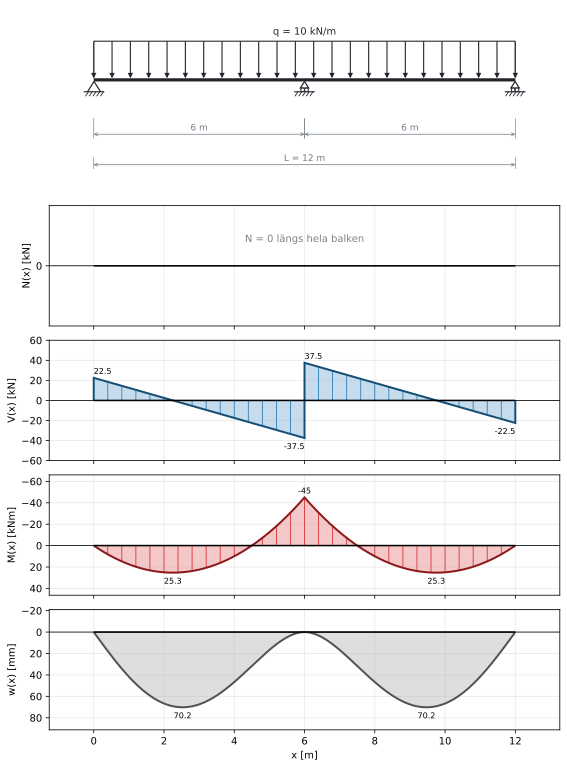

In [34]:
r = Balk(2 * L, EI).stöd(0, "led").stöd(L, "rull").stöd(2 * L, "rull").utbredd_last(q).lös()
kolla("R mittstöd", lambda: r.reaktioner[L]["V"], 10 * q * L / 8)
kolla("R ändstöd", lambda: r.reaktioner[0]["V"], 3 * q * L / 8)
kolla("M över mittstöd", lambda: r.M(L), -q * L**2 / 8)
kolla("w_max", lambda: r.extremvärden("w")[0][1], 0.00542 * q * L**4 / EI, rel=2e-3)
kolla("x för w_max", lambda: r.extremvärden("w")[0][0], 0.4215 * L, rel=2e-3)
visa(r)

## Gerberbalk med inre led

Inspänd i 0, led i 4, rullager i 6, q = 10 över hela balken. Delen 4–6 är fritt upplagd och ger 10 i leden. Konsolen 0–4 bär q och 10 i spetsen: R = 50, M_inspänning = 10·4²/2 + 10·4 = 120.

✔            R_V(0): fick 50, väntat 50
✔            R_M(0): fick 120, väntat 120
✔            M(0): fick -120, väntat -120
✔            M = 0 i leden: fick True, väntat True
✔            R(6): fick 10, väntat 10
✔            statiskt bestämd: fick 0, väntat 0


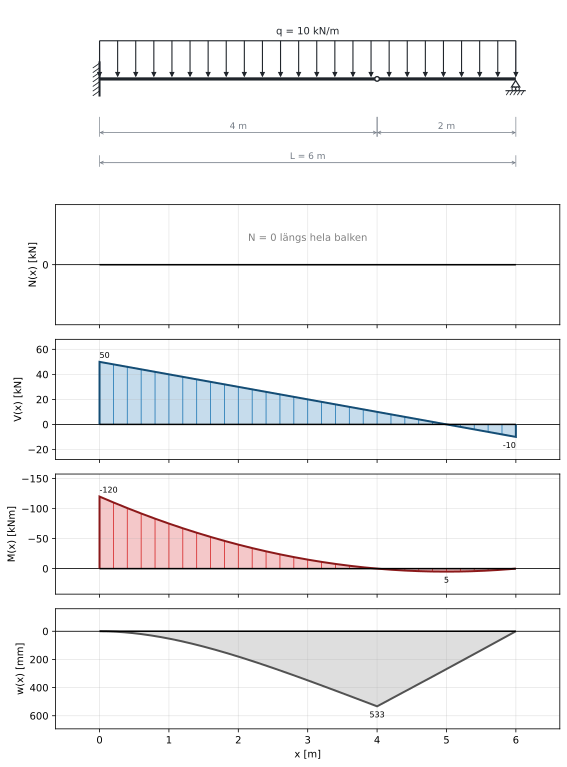

In [35]:
r = Balk(6, EI).stöd(0, "fast").led(4).stöd(6, "rull").utbredd_last(q).lös()
kolla("R_V(0)", lambda: r.reaktioner[0]["V"], 50)
kolla("R_M(0)", lambda: r.reaktioner[0]["M"], 120)
kolla("M(0)", lambda: r.M(0), -120)
kolla("M = 0 i leden", lambda: abs(r.M(4)) < 1e-9, True)
kolla("R(6)", lambda: r.reaktioner[6]["V"], 10)
kolla("statiskt bestämd", lambda: r.grad, 0)
visa(r)

## Punktmoment mitt på fritt upplagd balk

M0 = 12 moturs ger R_A = M0/L uppåt. Momentet gör ett språng från M0/2 till −M0/2.

✔            R_A: fick 2, väntat 2
✔            M strax vänster: fick 6, väntat 6
✔            M strax höger: fick -6, väntat -6


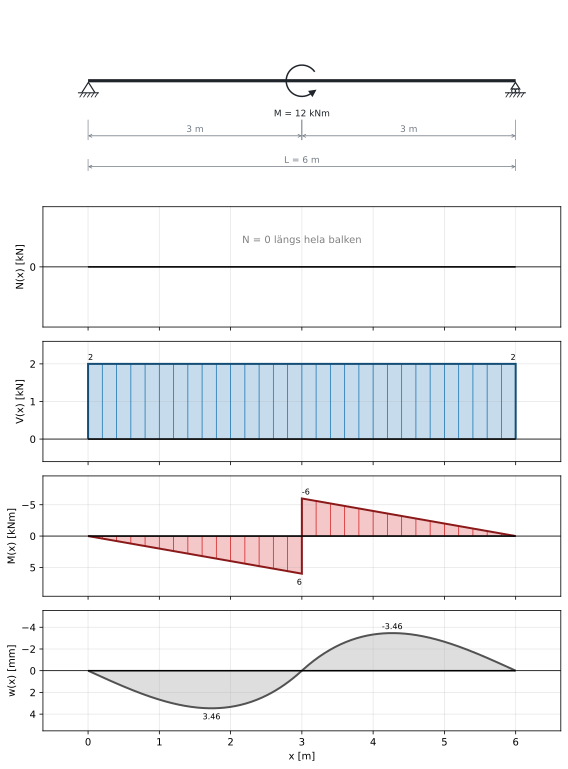

In [36]:
M0 = 12.0
r = Balk(L, EI).stöd(0, "led").stöd(L, "rull").moment(L / 2, M0).lös()
kolla("R_A", lambda: r.reaktioner[0]["V"], M0 / L)
kolla("M strax vänster", lambda: r.M(L / 2, "vänster"), M0 / 2)
kolla("M strax höger", lambda: r.M(L / 2), -M0 / 2)
visa(r)

## Triangellast från 0 till q

R_A = qL/6, R_B = qL/3, M_max = qL²/(9√3) vid x = L/√3.

✔            R_A: fick 10, väntat 10
✔            R_B: fick 20, väntat 20
✔            M_max: fick 23.094, väntat 23.094
✔            x för M_max: fick 3.4641, väntat 3.4641


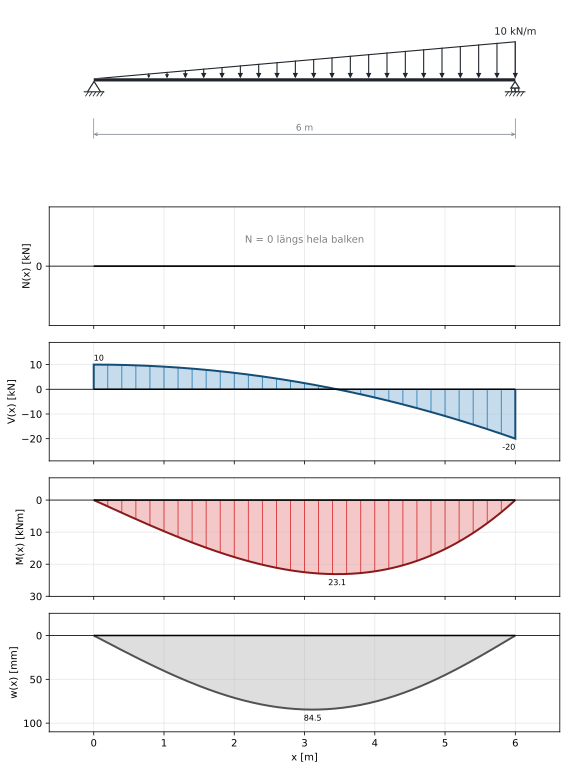

In [37]:
r = Balk(L, EI).stöd(0, "led").stöd(L, "rull").utbredd_last(0, q2=q).lös()
kolla("R_A", lambda: r.reaktioner[0]["V"], q * L / 6)
kolla("R_B", lambda: r.reaktioner[L]["V"], q * L / 3)
kolla("M_max", lambda: r.extremvärden("M")[0][1], q * L**2 / (9 * math.sqrt(3)))
kolla("x för M_max", lambda: r.extremvärden("M")[0][0], L / math.sqrt(3))
visa(r)

## Fritt upplagd balk, triangellast från q till 0

Kontroll av reaktioner och moment samt ritning i teknisk stil.

✔            Triangel R_A: fick 20, väntat 20
✔            Triangel R_B: fick 10, väntat 10
✔            Triangel M_max: fick 23.094, väntat 23.094
✔            Triangel x för M_max: fick 2.5359, väntat 2.5359


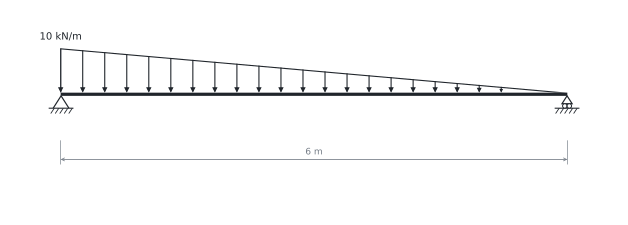

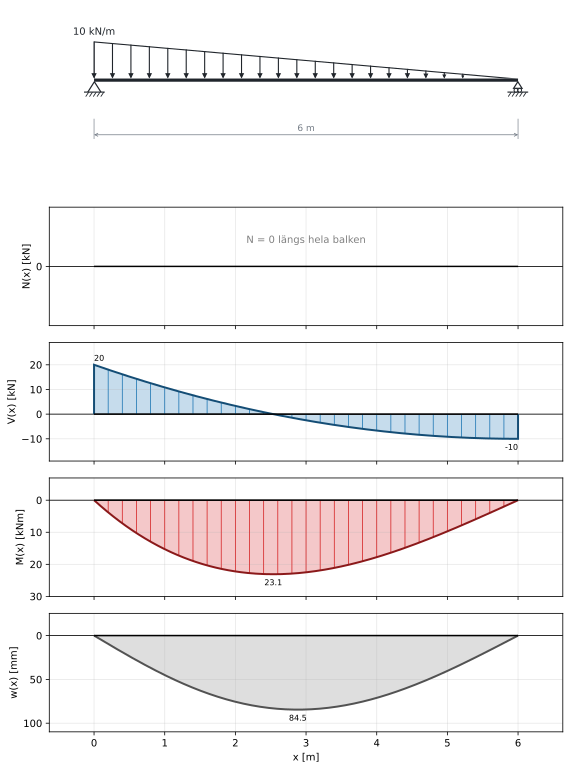

In [38]:
# Avtagande triangellast: nolländen ska nå balkens överkant vid höger stöd.
b = Balk(L, EI).stöd(0, "led").stöd(L, "rull").utbredd_last(q, q2=0)
r = b.lös()
kolla("Triangel R_A", lambda: r.reaktioner[0]["V"], q * L / 3)
kolla("Triangel R_B", lambda: r.reaktioner[L]["V"], q * L / 6)
kolla("Triangel M_max", lambda: r.extremvärden("M")[0][1], q * L**2 / (9 * math.sqrt(3)))
kolla("Triangel x för M_max", lambda: r.extremvärden("M")[0][0], L * (1 - 1 / math.sqrt(3)))
fig = b.rita_modell()
display(fig)
plt.close(fig)
visa(r)

## Jämvikt för en blandad balk

Summan av vertikala reaktioner ska vara lika med summan av lasterna.

✔            ΣV = 8·7 + 30 + 12·3/2: fick 104, väntat 104
✔            M = 0 i leden: fick True, väntat True


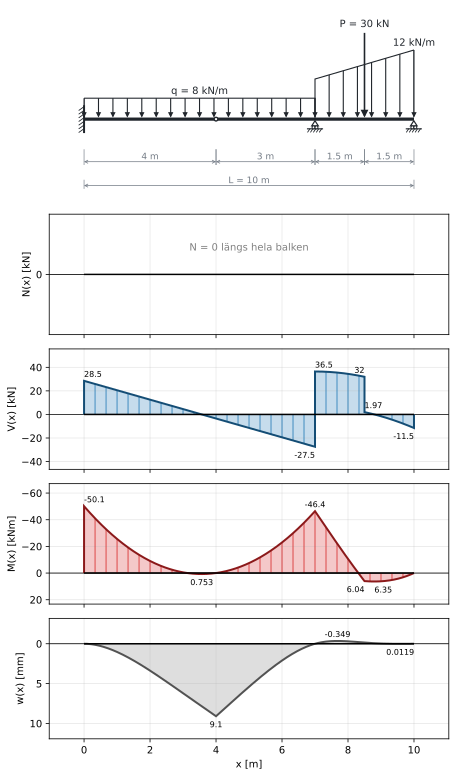

In [39]:
b = Balk(10, 20e3).stöd(0, "fast").led(4).stöd(7, "rull").stöd(10, "rull")
b.utbredd_last(8, 0, 7).punktlast(8.5, 30).utbredd_last(0, 7, 10, q2=12)
r = b.lös()
kolla("ΣV = 8·7 + 30 + 12·3/2", lambda: sum(R["V"] for R in r.reaktioner.values()), 104)
kolla("M = 0 i leden", lambda: abs(r.M(4)) < 1e-9, True)
visa(r)

## Normalkraft och felhantering

✔            N av dragande last: fick 15, väntat 15
✔            R_H: fick -15, väntat -15


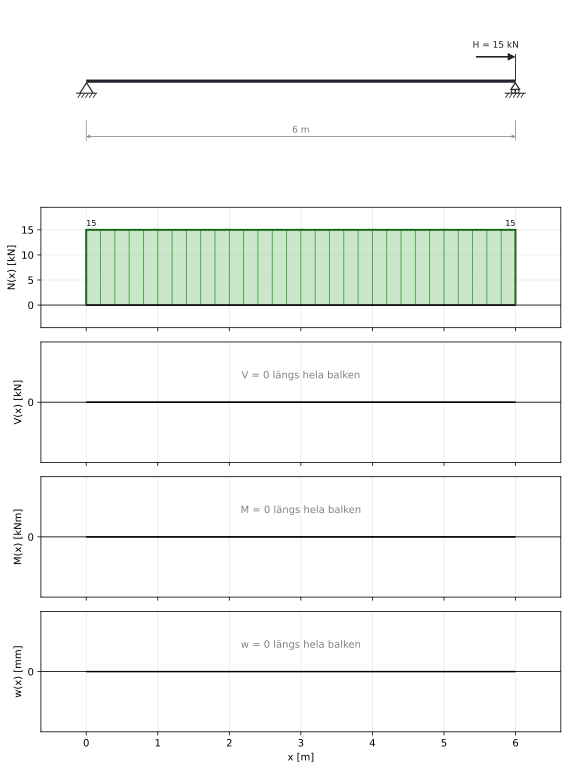

✔            mekanism: bara ett rullager: ValueError: Balken är en mekanism och kan inte bära lasten. Kontrollera stöd och leder.
✔            horisontell last utan fixlager: ValueError: Balken har horisontell last men inget stöd som tar horisontell kraft. Använd 'led' eller 'fast' för minst ett stöd.
✔            led i inspänning: ValueError: En inre led kan inte ligga i en inspänning (x = 3.0)
✔            last utanför balken: ValueError: Punktlasten vid x = 7.0 ligger utanför balken (0 ≤ x ≤ 6.0)
✔            okänd stödtyp: ValueError: Okänd stödtyp 'gungbräda'. Välj bland: fast, led, rull


In [40]:
r = Balk(L, EI, EA=1e5).stöd(0, "led").stöd(L, "rull").punktlast(L, 0, H=15).lös()
kolla("N av dragande last", lambda: r.N(3), 15)
kolla("R_H", lambda: r.reaktioner[0]["H"], -15)
visa(r)
kolla_fel("mekanism: bara ett rullager", lambda: Balk(L).stöd(3, "rull").punktlast(1, 1).lös())
kolla_fel("horisontell last utan fixlager", lambda: Balk(L).stöd(0, "rull").stöd(L, "rull").punktlast(2, 0, H=1).lös())
kolla_fel("led i inspänning", lambda: Balk(L).stöd(0, "fast").stöd(3, "fast").led(3).lös())
kolla_fel("last utanför balken", lambda: Balk(L).punktlast(7, 1))
kolla_fel("okänd stödtyp", lambda: Balk(L).stöd(0, "gungbräda"))

## Diagram

`rita()` ritar balken och valda diagram, standard är N, V, M och w. `rita_interaktiv()` ger en plotly-figur med samma diagram där muspekaren visar alla värden i samma x. Här kontrolleras bara att funktionerna ger rätt antal diagram.

In [41]:
import matplotlib.pyplot as plt
r = Balk(6, EI).stöd(0, "fast").led(4).stöd(6, "rull").utbredd_last(q).lös()
kolla("rita(): balk + 4 diagram", lambda: len(r.rita().axes), 5)
kolla("rita('VM', visa_balk=False)", lambda: len(r.rita("VM", visa_balk=False).axes), 2)
kolla("rita_M(): balk + M", lambda: len(r.rita_M().axes), 2)
kolla_fel("rita med okänt diagram", lambda: r.rita("X"))
plt.close("all")

try:
    import plotly
except ImportError:
    plotly = None
if plotly is None:
    print("plotly är inte installerat, hoppar över rita_interaktiv")
else:
    fig = r.rita_interaktiv()
    kolla("rita_interaktiv: en kurva per diagram", lambda: sum(t.mode == "lines" and t.hoverinfo != "skip" for t in fig.data), 4)
    kolla("rita_interaktiv: hover över alla diagram",
          lambda: (fig.layout.hovermode, fig.layout.hoversubplots), ("x unified", "axis"))

✔            rita(): balk + 4 diagram: fick 5, väntat 5
✔            rita('VM', visa_balk=False): fick 2, väntat 2
✔            rita_M(): balk + M: fick 2, väntat 2
✔            rita med okänt diagram: ValueError: Okända diagram ['X'], välj bland N, V, M och w
✔            rita_interaktiv: en kurva per diagram: fick 4, väntat 4
✔            rita_interaktiv: hover över alla diagram: fick ('x unified', 'axis'), väntat ('x unified', 'axis')


## Sammanfattning

Cellen stoppar med `AssertionError` om någon kontroll som inte är märkt som känt fel misslyckas.

In [42]:
sammanfattning()

59 av 59 kontroller gick igenom.

Inga oväntade fel.


## Användningsexempel

Exemplen nedan kan ändras och köras efter testernas sammanfattning. Varje kodcell bygger sin egen balk.

Här används **m, kN och kNm**, med böjstyvheten **EI i kNm²**. Nedåtriktade laster är positiva. `rita_modell()` visar den tekniska ritningen och `lös()` beräknar reaktioner och snittkrafter.

### 1. Fritt upplagd balk med jämnt utbredd last

En 6 m lång balk med ledstöd till vänster, rullstöd till höger och 10 kN/m över hela längden. Här visas även hur reaktioner och moment hämtas.

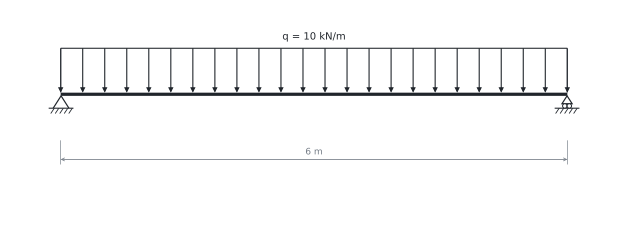

Vänster reaktion: 30.00 kN
Höger reaktion: 30.00 kN
Moment i mitten: 45.00 kNm


In [43]:
from kthbygg.balk import Balk
import matplotlib.pyplot as plt

balk_jamn = Balk(6, EI=40000)
balk_jamn.stöd(0, "led").stöd(6, "rull")
balk_jamn.utbredd_last(10)

fig = balk_jamn.rita_modell()
display(fig)
plt.close(fig)

resultat = balk_jamn.lös()
print(f"Vänster reaktion: {resultat.reaktioner[0]['V']:.2f} kN")
print(f"Höger reaktion: {resultat.reaktioner[6]['V']:.2f} kN")
print(f"Moment i mitten: {resultat.M(3):.2f} kNm")

### 2. Fritt upplagd balk med triangulär last

Lasten ökar från 0 till 6 kN/m. Byt till `utbredd_last(6, q2=0)` för att vända triangeln. Maxvärdet visas vid lastens högsta ände.

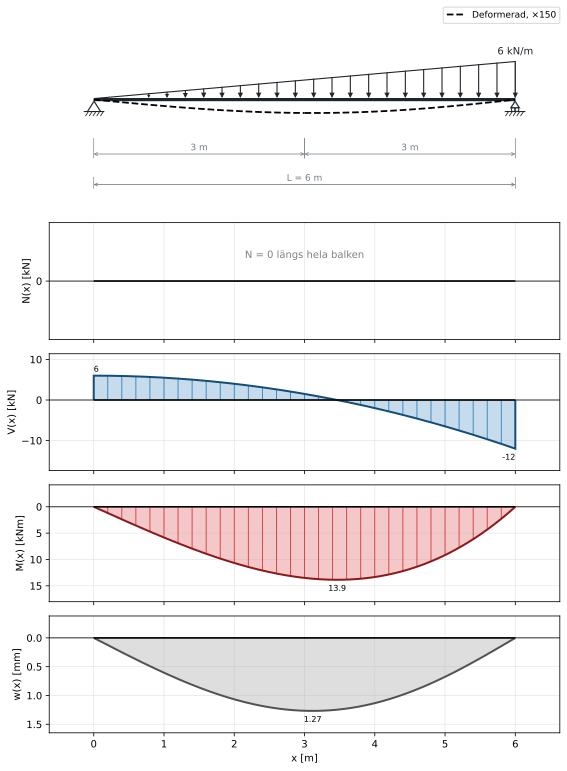

In [44]:
from kthbygg.balk import Balk
import matplotlib.pyplot as plt

balk_triangel = Balk(6, EI=40000)
balk_triangel.stöd(0, "led").stöd(6, "rull")
balk_triangel.utbredd_last(0, q2=6)
balk_triangel.punktlast(x=3, P=0,)

resultat_triangel = balk_triangel.lös()
fig = resultat_triangel.rita("NVMw", visa_balk=True, deformerad=True)
resultat_triangel.rita_interaktiv("VMw")
fig = resultat_triangel.rita_interaktiv("VMw")
fig.show()


### 3. Konsol med punktlast och moment

En 4 m lång konsol med 12 kN nedåt och ett moment på 8 kNm moturs i den fria änden. `matt=False` döljer längdmåtten. Avkommentera `savefig` om du vill spara ritningen som SVG.

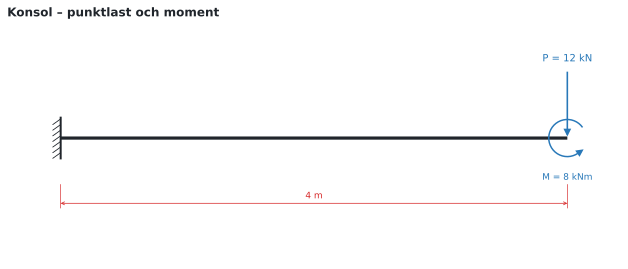

In [45]:
from kthbygg.balk import Balk
import matplotlib.pyplot as plt

konsol_exempel = Balk(4, EI=40000)
konsol_exempel.stöd(0, "fast")
konsol_exempel.punktlast(4, 12).moment(4, 8)
konsol_exempel.rita_modell(färgat=True, titel="Konsol – punktlast och moment")

### 4. Olika EI och EA längs balken

Konsol med lägre böj- och axialstyvhet på den yttre halvan. Indata i m och kN; EI i kNm² och EA i kN.

w(4) = 7.200 mm
u(4) = 0.300 mm


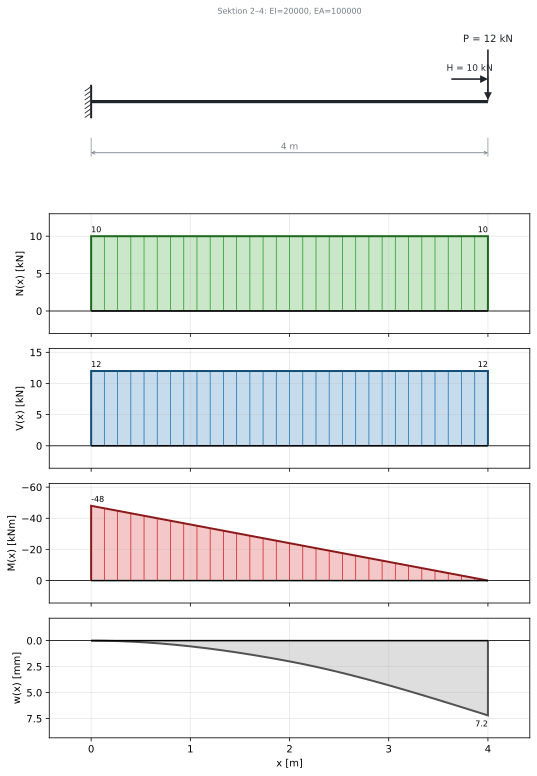

In [46]:
from kthbygg.balk import Balk
import matplotlib.pyplot as plt

balk_delar = Balk(4, EI=40000, EA=200000)
balk_delar.stöd(0, "fast")
balk_delar.sektion(2, 4, EI=20000, EA=100000)
balk_delar.punktlast(4, 12, H=10)
r_delar = balk_delar.lös()
print(f"w(4) = {1000*r_delar.w(4):.3f} mm")
print(f"u(4) = {1000*r_delar.förskjutningar[4]['u']:.3f} mm")
r_delar.rita()
plt.show()


### 5. Konsol med fjäderstöd

En vertikal fjäder i spetsen med ky = 1000 kN/m. kx anger axialfjäder och kr rotationsfjäder (kNm/rad).

w(4) = 4.174 mm
Reaktioner: {0.0: {'V': np.float64(7.826086956521735), 'H': np.float64(0.0), 'M': np.float64(31.304347826086943)}, 4.0: {'V': np.float64(4.17391304347826), 'H': np.float64(0.0), 'M': np.float64(0.0)}}


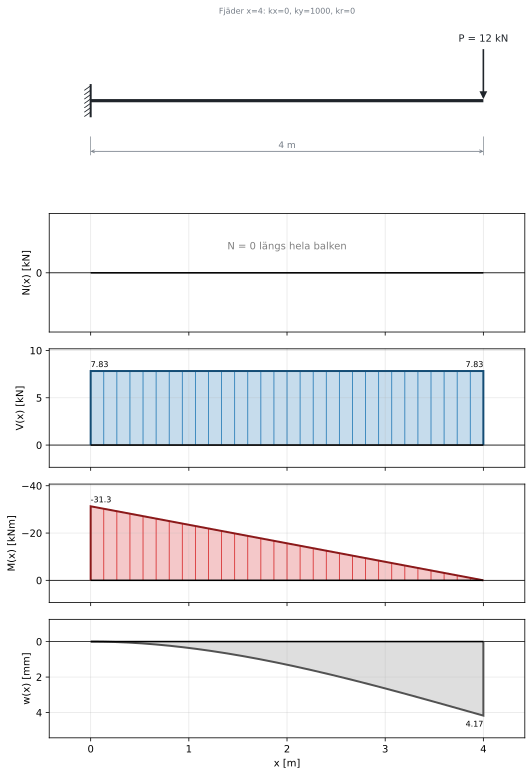

In [47]:
from kthbygg.balk import Balk
import matplotlib.pyplot as plt

balk_fjader = Balk(4, EI=40000)
balk_fjader.stöd(0, "fast").fjäderstöd(4, ky=1000)
balk_fjader.punktlast(4, 12)
r_fjader = balk_fjader.lös()
print(f"w(4) = {1000*r_fjader.w(4):.3f} mm")
print("Reaktioner:", r_fjader.reaktioner)
r_fjader.rita()
plt.show()


### 6. Fri och hindrad värmeutvidgning

Samma balk värms 30 °C. Fri spets ger utvidgning; inspänning i båda ändar ger tryckkraft. Alfa = 12·10⁻⁶ /°C.

Fri värmeutvidgning
u(4) = 1.440 mm, N = 0.000 kN


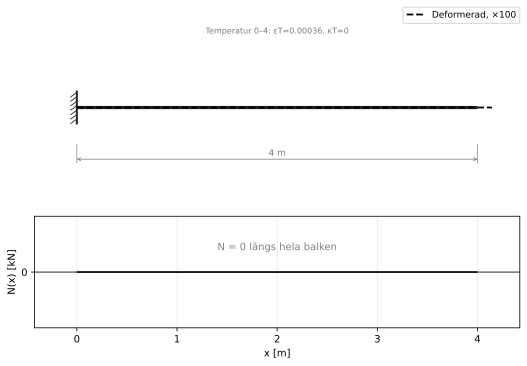

Hindrad värmeutvidgning
u(4) = 0.000 mm, N = -72.000 kN


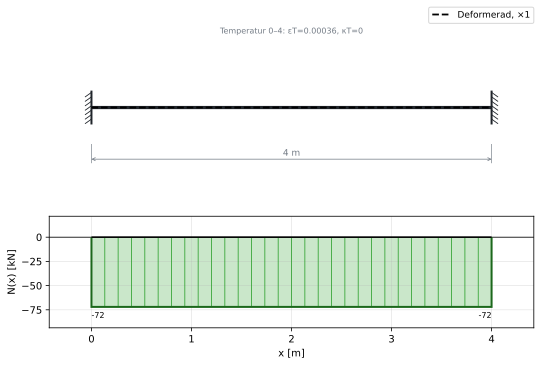

In [48]:
from kthbygg.balk import Balk
import matplotlib.pyplot as plt

for hindrad in (False, True):
    balk_varme = Balk(4, EI=40000, EA=200000)
    balk_varme.stöd(0, "fast")
    if hindrad:
        balk_varme.stöd(4, "fast")
    balk_varme.temperatur(30, alfa=12e-6)
    r_varme = balk_varme.lös()
    print("Hindrad" if hindrad else "Fri", "värmeutvidgning")
    print(f"u(4) = {1000*r_varme.förskjutningar[4]['u']:.3f} mm, N = {r_varme.N(2):.3f} kN")
    r_varme.rita("N", deformerad=True)
    plt.show()


### 7. Temperaturgradient

Konsol med temperaturgradient 50 °C/m genom tvärsnittet. Temperaturgradienten ger krökning även utan mekanisk last.

w(4) = -4.800 mm


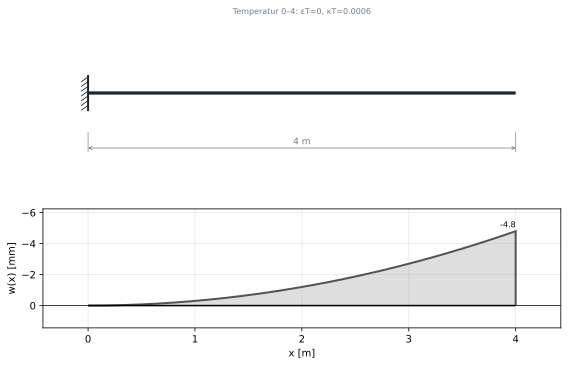

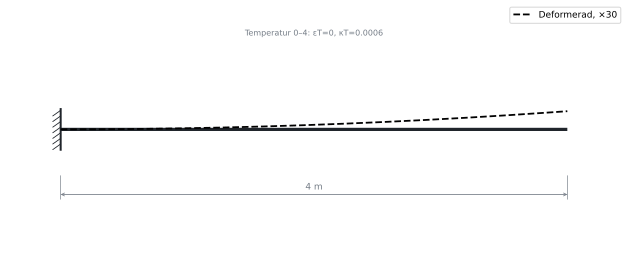

In [49]:
from kthbygg.balk import Balk
import matplotlib.pyplot as plt

balk_gradient = Balk(4, EI=40000, EA=200000)
balk_gradient.stöd(0, "fast").temperatur(gradient=50, alfa=12e-6)
r_gradient = balk_gradient.lös()
print(f"w(4) = {1000*r_gradient.w(4):.3f} mm")
r_gradient.rita("w")
plt.show()
r_gradient.rita_deformerad()
plt.show()


### 8. Portalram med pelare och sned balk

Noder i m och laster i kN. Pelarna och takbalken har olika styvheter. Nodlast Fy är positiv uppåt; utbredd last q är positiv i stångens lokala negativa y-riktning.

Nodförskjutningar (m, rad): {1: {'ux': np.float64(0.0), 'uy': np.float64(0.0), 'rotation': np.float64(0.0)}, 2: {'ux': np.float64(0.0010946279321007702), 'uy': np.float64(-0.00017370187452803024), 'rotation': np.float64(-0.00046038745197274496)}, 3: {'ux': np.float64(0.0010463233163759337), 'uy': np.float64(-0.00036839750062929303), 'rotation': np.float64(6.463478134785166e-05)}, 4: {'ux': np.float64(0.0), 'uy': np.float64(0.0), 'rotation': np.float64(0.0)}}


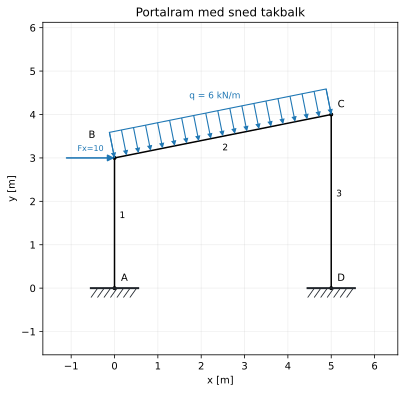

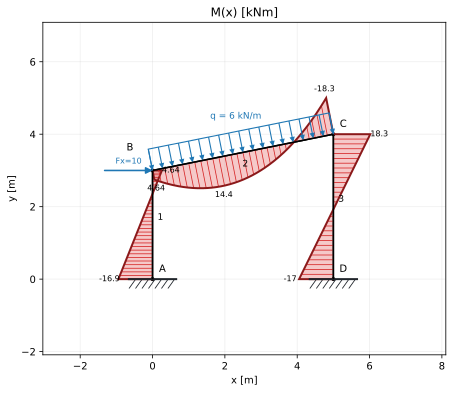

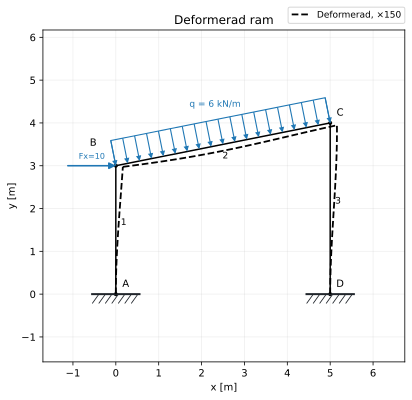

In [50]:
from kthbygg.ram import Ram
import matplotlib.pyplot as plt

portal = Ram(EI=40000, EA=200000)
portal.nod(1, 0, 0).nod(2, 0, 3).nod(3, 5, 4).nod(4, 5, 0)
portal.stång(1, 1, 2)
portal.stång(2, 2, 3, EI=60000, EA=300000)
portal.stång(3, 4, 3)
portal.stöd(1, "fast").stöd(4, "fast")
portal.utbredd_last(2, 6)
portal.nodlast(2, Fx=10)
r_portal = portal.lös()
print("Nodförskjutningar (m, rad):", r_portal.förskjutningar)
portal.rita_modell(titel="Portalram med sned takbalk")
plt.show()
r_portal.rita("M")
plt.show()
r_portal.rita_deformerad()
plt.show()


### 9. Vinklad punktkraft på en balk

En kraft F = 10 kN verkar i konsolens spets vid x = 4 m. Vinkeln räknas moturs från positiva globala x-axeln: −30° är snett nedåt åt höger. H = Fx och P = −Fy eftersom P är positiv nedåt. Ritningen visar kraftens två komponenter.

Fx = 8.660 kN, Fy = -5.000 kN


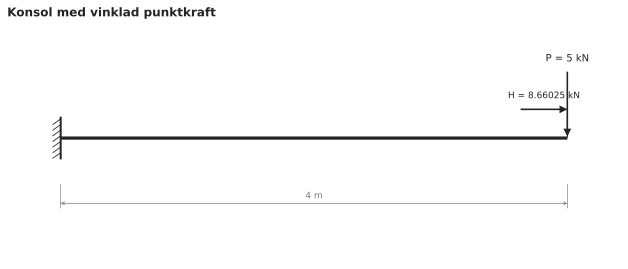

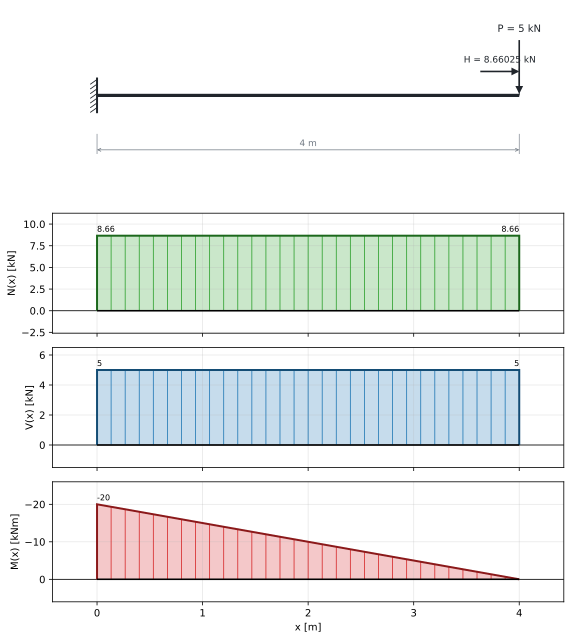

In [51]:
import math
import matplotlib.pyplot as plt
from kthbygg.balk import Balk

F = 10.0  # kN
vinkel = -30.0  # grader, moturs från positiva x-axeln
alfa = math.radians(vinkel)
Fx = F * math.cos(alfa)
Fy = F * math.sin(alfa)

balk_vinkel = Balk(4, EI=40000, EA=200000)
balk_vinkel.stöd(0, "fast")
balk_vinkel.punktlast(4, H=Fx, P=-Fy)
resultat_vinkel = balk_vinkel.lös()
print(f"Fx = {Fx:.3f} kN, Fy = {Fy:.3f} kN")
balk_vinkel.rita_modell(titel="Konsol med vinklad punktkraft")
plt.show()
resultat_vinkel.rita("NVM")
plt.show()


### 10. Vinklad nodkraft på en ram

Samma kraft verkar i nod B på en konsolpelare. Vinkeln avser globala x-axeln, oavsett stångens riktning. Fx är positiv åt höger och Fy positiv uppåt. Ritningen visar kraftens två komponenter.

Fx = 8.660 kN, Fy = -5.000 kN


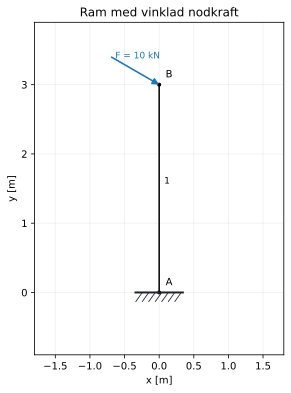

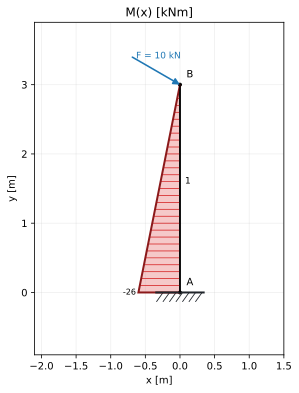

In [52]:
import math
import matplotlib.pyplot as plt
from kthbygg.ram import Ram

F = 10.0  # kN
vinkel = -30.0  # grader, moturs från positiva x-axeln
alfa = math.radians(vinkel)
Fx = F * math.cos(alfa)
Fy = F * math.sin(alfa)

ram_vinkel = Ram(EI=40000, EA=200000)
ram_vinkel.nod("A", 0, 0).nod("B", 0, 3)
ram_vinkel.stång(1, "A", "B")
ram_vinkel.stöd("A", "fast")
ram_vinkel.nodlast("B", F=10, vinkel=-30)
resultat_ram_vinkel = ram_vinkel.lös()
print(f"Fx = {Fx:.3f} kN, Fy = {Fy:.3f} kN")
ram_vinkel.rita_modell(titel="Ram med vinklad nodkraft")
plt.show()
resultat_ram_vinkel.rita("M")
plt.show()
